# Noise Removal and Sharpening in Face Recognition Systems

**Dataset:** Extended Yale Face Database B (5 subjects, 25 aligned grayscale images per subject, 125 images total)  
**Pipeline Architecture:**
1. **Module 1 – Face Alignment (`alignment.py`):** Haar Cascade face detection + LBF 68-landmark eye alignment and 256×256 cropping.
2. **Module 2 – Noise Removal (`noise_removal.py`):** Synthetic Gaussian and Salt & Pepper noise injection, followed by Gaussian, Median, Bilateral, and Non-Local Means filtering.
3. **Module 3 – Detail Sharpening (`sharpening.py`):** Unsharp Masking and Laplacian sharpening evaluated with Variance of Laplacian and Tenengrad metrics.
4. **Module 4 – Evaluation & Visualization (`evaluation.py`, `app.py`):** Lighting-angle train/test split, LBPH face recognition benchmark, histogram analysis, and failure-case inspection.


In [1]:
import os
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

for candidate in [os.getcwd(), os.path.abspath("..")]:
    if os.path.isfile(os.path.join(candidate, "evaluation.py")):
        if candidate not in sys.path:
            sys.path.insert(0, candidate)
        break

from evaluation import (
    load_dataset,
    run_single_pipeline,
    run_full_benchmark,
)

plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"


## 1. Dataset Overview & Lighting-Angle Split
Each subject's aligned images are sorted by illumination angle $\sqrt{\text{Azimuth}^2 + \text{Elevation}^2}$. The 60% most frontal/well-lit images form the **training set** (75 images), while the 40% more challenging angled/shadowed images form the **test set** (50 images).


In [2]:
train_data, test_data, label_map = load_dataset()

print(f"Subjects: {len(label_map)} ({list(label_map.values())})")
print(f"Training images: {len(train_data)} | Test images: {len(test_data)}")
print(f"Mean lighting angle -> Train: {np.mean([x['angle'] for x in train_data]):.1f}° | Test: {np.mean([x['angle'] for x in test_data]):.1f}°")


Subjects: 5 (['person_01', 'person_02', 'person_03', 'person_04', 'person_05'])
Training images: 75 | Test images: 50
Mean lighting angle -> Train: 38.6° | Test: 90.4°


## 2. Stage-by-Stage Visual & Pixel Histogram Comparison
Below we inspect a challenging test image across all four processing stages (*Original -> Noisy -> Denoised -> Sharpened*) together with its pixel intensity histograms and quality metrics.


Sample image: person_01 / yaleB17_P00A-070E+45.png (Lighting Angle: 83.2°)


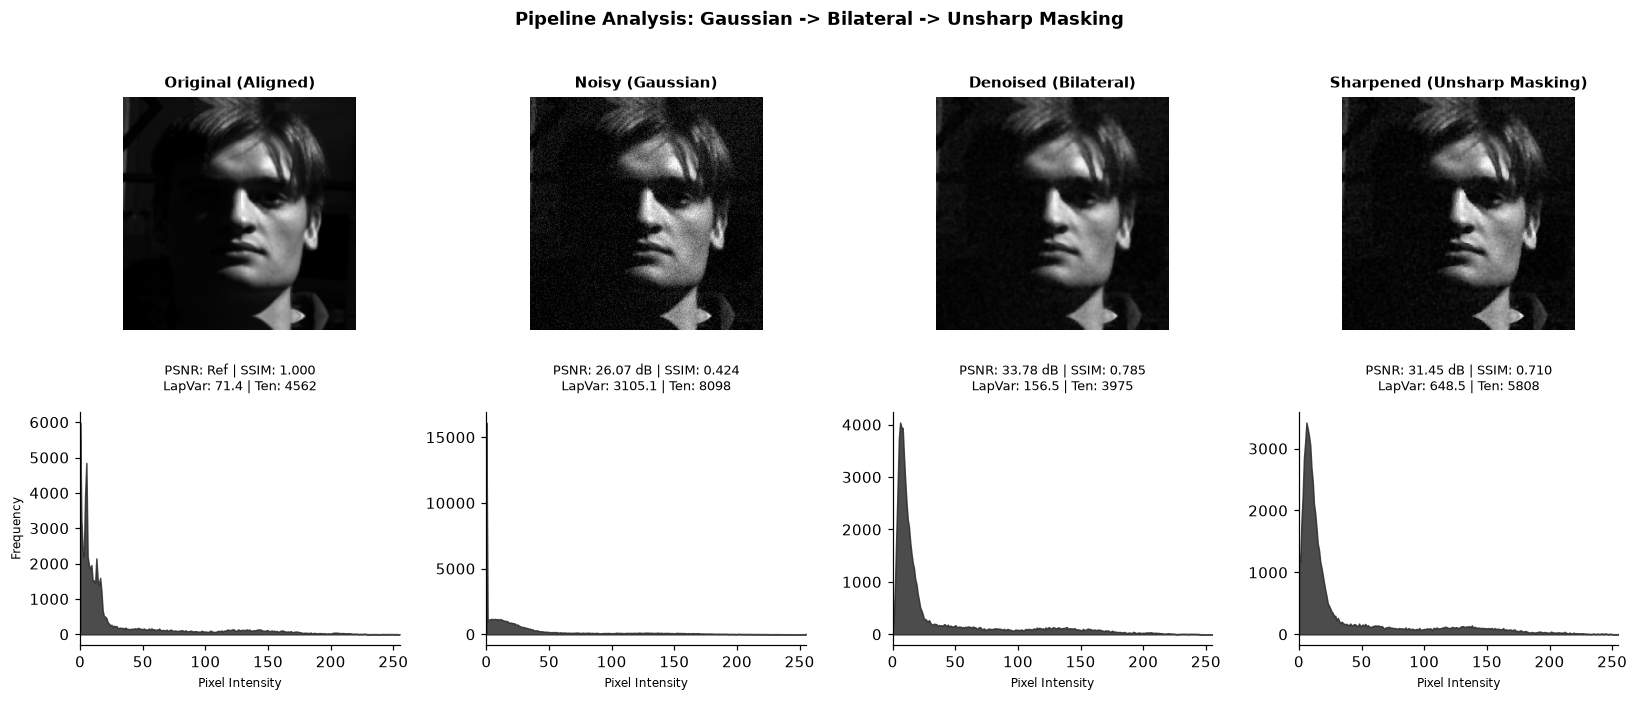

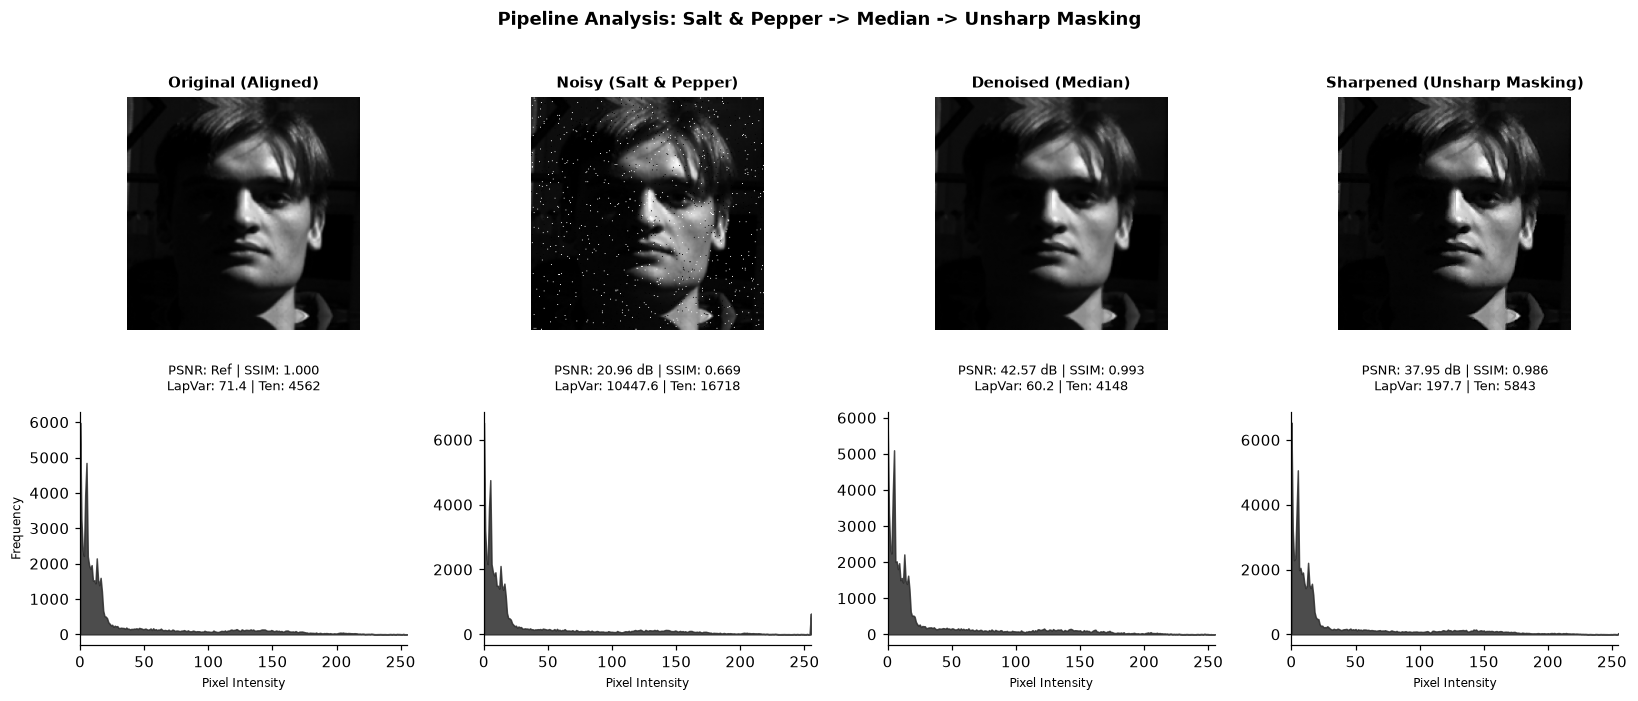

In [3]:
def show_pipeline_comparison(sample_img, noise_type, denoise_method, sharpen_method):
    res = run_single_pipeline(
        sample_img,
        noise_type=noise_type,
        denoise_method=denoise_method,
        sharpen_method=sharpen_method,
        seed=42,
    )
    stages = [
        ("Original (Aligned)", "original"),
        (f"Noisy ({noise_type})", "noisy"),
        (f"Denoised ({denoise_method})", "denoised"),
        (f"Sharpened ({sharpen_method})", "sharpened"),
    ]

    fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), dpi=110)
    for col, (title, key) in enumerate(stages):
        img = res[key]
        m = res["metrics"][key]
        psnr_str = "Ref" if not np.isfinite(m["psnr"]) else f"{m['psnr']:.2f} dB"

        axes[0, col].imshow(img, cmap="gray", vmin=0, vmax=255)
        axes[0, col].set_title(title, fontsize=10, fontweight="bold")
        axes[0, col].axis("off")
        axes[0, col].text(
            0.5, -0.14,
            f"PSNR: {psnr_str} | SSIM: {m['ssim']:.3f}\nLapVar: {m['lap_var']:.1f} | Ten: {m['tenengrad']:.0f}",
            transform=axes[0, col].transAxes,
            ha="center", va="top", fontsize=8.5,
        )

        hist = cv2.calcHist([img], [0], None, [256], [0, 256]).ravel()
        axes[1, col].fill_between(range(256), hist, color="#2C2C2C", alpha=0.85)
        axes[1, col].set_xlim(0, 255)
        axes[1, col].set_xlabel("Pixel Intensity", fontsize=8)
        if col == 0:
            axes[1, col].set_ylabel("Frequency", fontsize=8)
        axes[1, col].spines["top"].set_visible(False)
        axes[1, col].spines["right"].set_visible(False)

    plt.suptitle(f"Pipeline Analysis: {noise_type} -> {denoise_method} -> {sharpen_method}", fontsize=12, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()

sample = test_data[0]
print(f"Sample image: {sample['person']} / {sample['filename']} (Lighting Angle: {sample['angle']:.1f}°)")
show_pipeline_comparison(sample["image"], "Gaussian", "Bilateral", "Unsharp Masking")
show_pipeline_comparison(sample["image"], "Salt & Pepper", "Median", "Unsharp Masking")


## 3. Full Quantitative Benchmark & LBPH Face Recognition Evaluation
We evaluate all classical denoising and sharpening combinations on the entire 50-image test set under identical noise seeds for both **Gaussian** ($\sigma = 15$) and **Salt & Pepper** ($2\%$) noise.


In [4]:
df_gauss, details_gauss, _ = run_full_benchmark(noise_type="Gaussian", sigma=15)
df_sp, details_sp, _ = run_full_benchmark(noise_type="Salt & Pepper", sp_amount=0.02)

print("=== GAUSSIAN NOISE BENCHMARK (sigma=15) ===")
display(df_gauss)

print("\n=== SALT & PEPPER NOISE BENCHMARK (ratio=0.02) ===")
display(df_sp)


=== GAUSSIAN NOISE BENCHMARK (sigma=15) ===


,Method,Avg PSNR (dB),Avg SSIM,Avg Laplacian Var,Avg Tenengrad,Avg Contrast,LBPH Accuracy (%),Correct / Total
0,Original (Clean),NaN,1.0000,68.83,3796.79,47.48,88.0,44/50
1,Noisy (Gaussian),26.29,0.3818,2929.07,7077.52,47.66,56.0,28/50
2,Gaussian Filter,32.66,0.6855,80.29,3719.75,45.92,58.0,29/50
3,Median Filter,32.65,0.7295,239.91,4056.37,47.05,90.0,45/50
4,Bilateral Filter,33.91,0.7458,147.68,3335.46,45.85,80.0,40/50
5,NL-Means Filter,27.65,0.4894,2157.51,6154.78,47.26,56.0,28/50
6,Bilateral + Unsharp,31.67,0.6700,594.72,5029.76,46.69,82.0,41/50
7,Bilateral + Laplacian,28.64,0.5779,921.97,7973.23,47.78,38.0,19/50
8,NL-Means + Unsharp,22.51,0.3037,8160.52,12702.07,50.01,32.0,16/50
9,NL-Means + Laplacian,18.23,0.1834,17252.10,28251.82,55.06,18.0,9/50



=== SALT & PEPPER NOISE BENCHMARK (ratio=0.02) ===


,Method,Avg PSNR (dB),Avg SSIM,Avg Laplacian Var,Avg Tenengrad,Avg Contrast,LBPH Accuracy (%),Correct / Total
0,Original (Clean),NaN,1.0000,68.83,3796.79,47.48,88.0,44/50
1,Noisy (Salt & Pepper),20.66,0.6458,11182.70,16866.05,52.58,90.0,45/50
2,Gaussian Filter,28.71,0.7026,246.43,5960.41,47.13,90.0,45/50
3,Median Filter,43.03,0.9923,55.40,3390.91,47.29,90.0,45/50
4,Bilateral Filter,20.79,0.6510,10743.91,15679.67,51.99,90.0,45/50
5,NL-Means Filter,20.65,0.6353,11150.44,16736.35,52.53,86.0,43/50
6,Bilateral + Unsharp,20.54,0.6327,12325.59,17022.52,53.16,90.0,45/50
7,Bilateral + Laplacian,20.21,0.6149,11714.17,19679.93,53.93,86.0,43/50
8,NL-Means + Unsharp,20.47,0.6189,12561.75,18143.35,53.63,86.0,43/50
9,NL-Means + Laplacian,19.89,0.5859,12390.69,21973.75,54.67,86.0,43/50


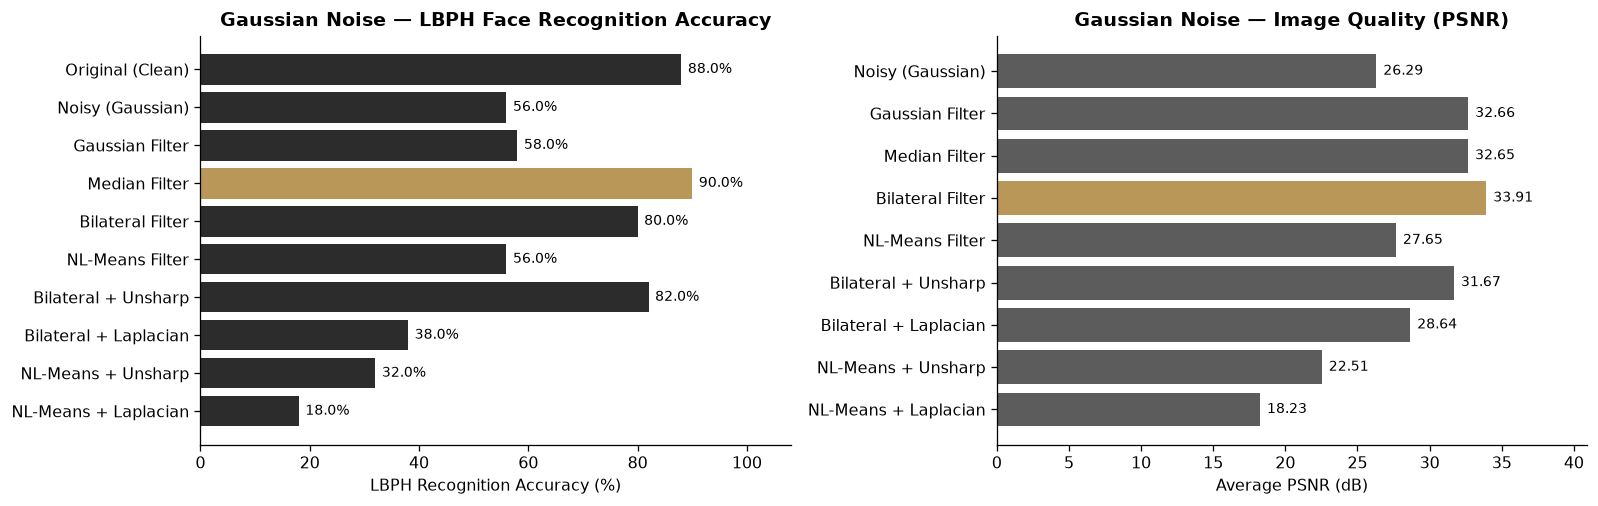

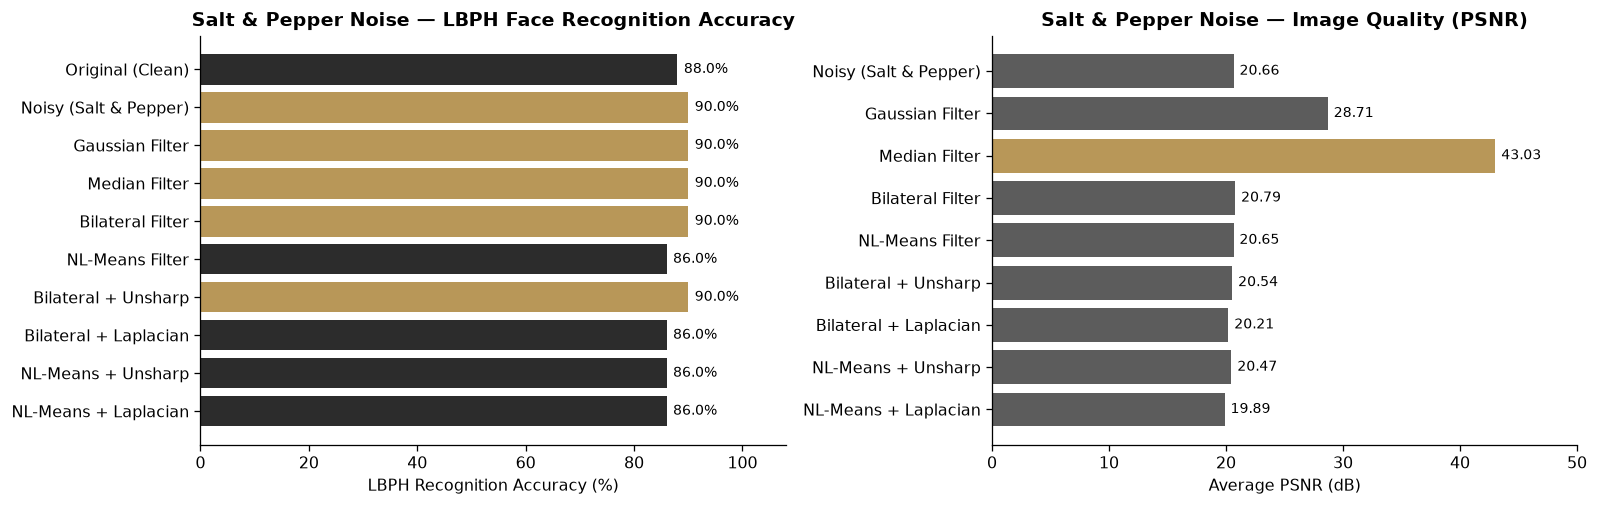

In [5]:
def plot_benchmark_charts(df, noise_title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), dpi=115)

    acc_colors = ["#B89758" if v == df["LBPH Accuracy (%)"].max() else "#2C2C2C" for v in df["LBPH Accuracy (%)"]]
    bars1 = axes[0].barh(df["Method"][::-1], df["LBPH Accuracy (%)"][::-1], color=acc_colors[::-1])
    axes[0].set_xlim(0, 108)
    axes[0].set_xlabel("LBPH Recognition Accuracy (%)")
    axes[0].set_title(f"{noise_title} — LBPH Face Recognition Accuracy", fontweight="bold")
    axes[0].spines["top"].set_visible(False)
    axes[0].spines["right"].set_visible(False)
    for bar in bars1:
        w = bar.get_width()
        axes[0].text(w + 1.2, bar.get_y() + bar.get_height() / 2, f"{w:.1f}%", va="center", fontsize=8.5)

    df_p = df.dropna(subset=["Avg PSNR (dB)"])
    psnr_colors = ["#B89758" if v == df_p["Avg PSNR (dB)"].max() else "#5C5C5C" for v in df_p["Avg PSNR (dB)"]]
    bars2 = axes[1].barh(df_p["Method"][::-1], df_p["Avg PSNR (dB)"][::-1], color=psnr_colors[::-1])
    axes[1].set_xlim(0, df_p["Avg PSNR (dB)"].max() + 7)
    axes[1].set_xlabel("Average PSNR (dB)")
    axes[1].set_title(f"{noise_title} — Image Quality (PSNR)", fontweight="bold")
    axes[1].spines["top"].set_visible(False)
    axes[1].spines["right"].set_visible(False)
    for bar in bars2:
        w = bar.get_width()
        axes[1].text(w + 0.5, bar.get_y() + bar.get_height() / 2, f"{w:.2f}", va="center", fontsize=8.5)

    plt.tight_layout()
    plt.show()

plot_benchmark_charts(df_gauss, "Gaussian Noise")
plot_benchmark_charts(df_sp, "Salt & Pepper Noise")


## 4. Failure Case & Error Analysis
Inspecting misclassified faces explains the real-world trade-offs of classical pipelines:
- **Severe Side Lighting (70°–90°):** Half of the face falls into deep shadow, distorting local binary patterns (LBPH) even after filtering.
- **Noise Amplification via Over-Sharpening:** When residual noise remains (e.g., `NL-Means` under Gaussian noise with low $h=6$), applying **Laplacian Sharpening** amplifies high-frequency noise instead of facial edges, dropping LBPH accuracy from **88.0%** down to **18.0%**.
- **Filter-Noise Mismatch:** Under Salt & Pepper noise, **Median Filter** achieves **43.03 dB PSNR / 0.9923 SSIM**, whereas Bilateral and NL-Means treat impulse dots as edges and fail to remove them.


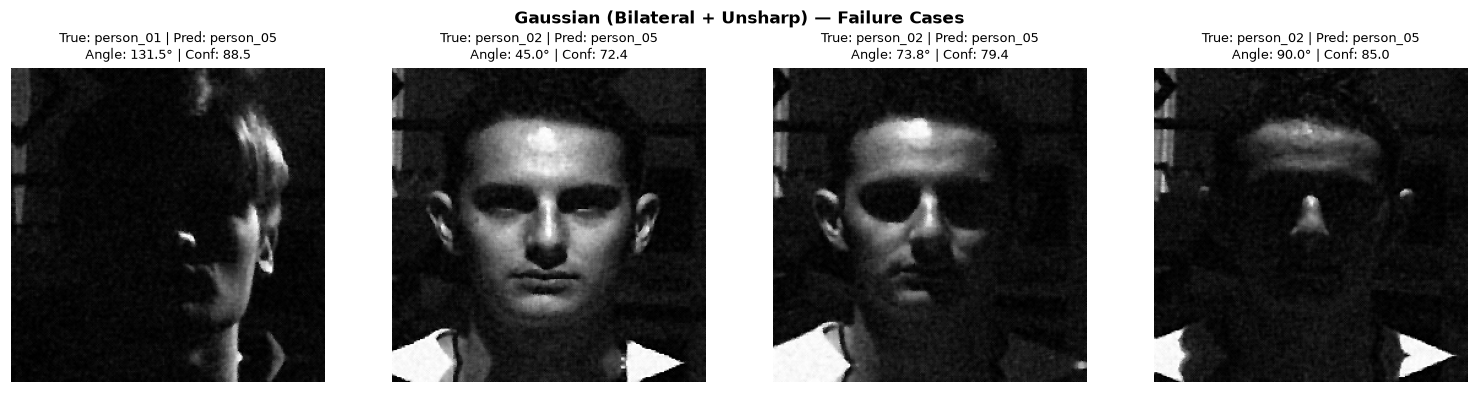

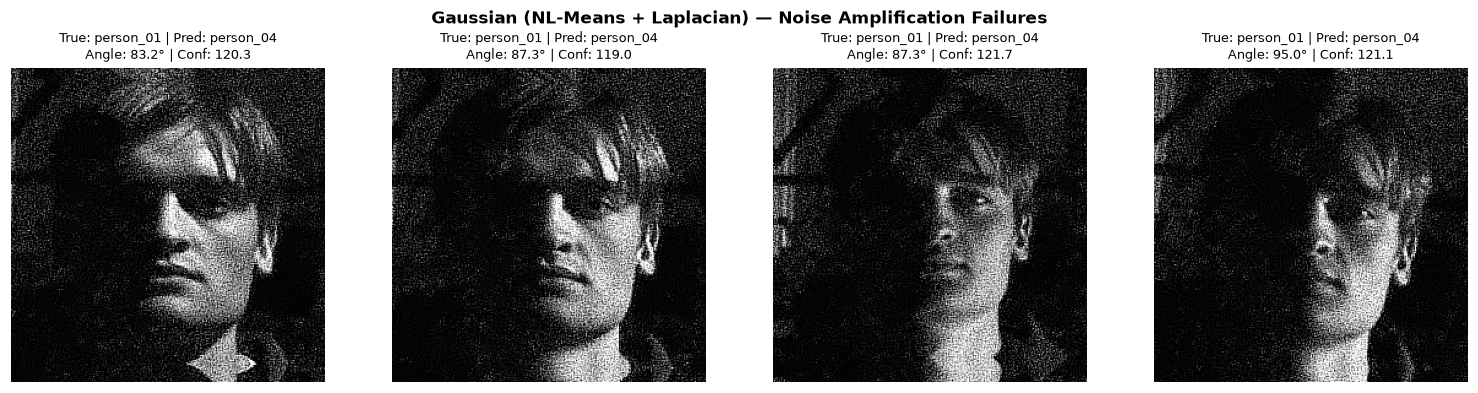

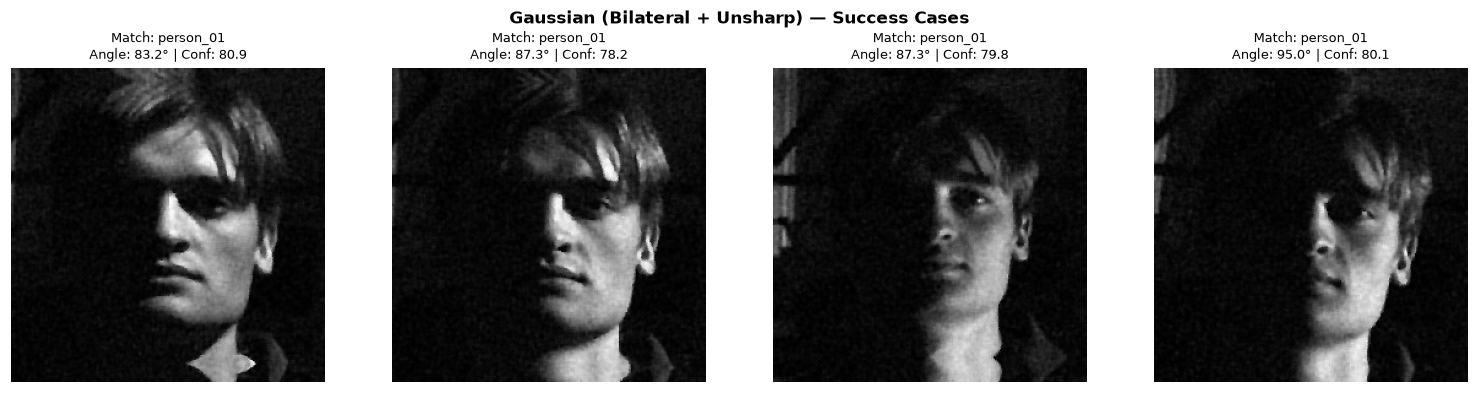

In [6]:
def show_cases(records, title, show_failures=True, limit=4):
    subset = [r for r in records if (not r["correct"] if show_failures else r["correct"])][:limit]
    if not subset:
        print(f"{title}: No cases to display.")
        return

    fig, axes = plt.subplots(1, len(subset), figsize=(3.5 * len(subset), 3.6), dpi=110)
    if len(subset) == 1:
        axes = [axes]
    for ax, rec in zip(axes, subset):
        ax.imshow(rec["processed"], cmap="gray", vmin=0, vmax=255)
        ax.axis("off")
        status = f"True: {rec['true_person']} | Pred: {rec['pred_person']}" if show_failures else f"Match: {rec['true_person']}"
        ax.set_title(f"{status}\nAngle: {rec['angle']:.1f}° | Conf: {rec['confidence']:.1f}", fontsize=8.5)
    plt.suptitle(title, fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()

show_cases(details_gauss["Bilateral + Unsharp"], "Gaussian (Bilateral + Unsharp) — Failure Cases", show_failures=True)
show_cases(details_gauss["NL-Means + Laplacian"], "Gaussian (NL-Means + Laplacian) — Noise Amplification Failures", show_failures=True)
show_cases(details_gauss["Bilateral + Unsharp"], "Gaussian (Bilateral + Unsharp) — Success Cases", show_failures=False)


## 5. Interactive Dashboard
For live demonstration and parameter exploration, launch the minimalist Streamlit panel from the project root:

    python -m streamlit run app.py
